# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Computer Vision Lab** | Registration No: 022 | Name: Muhammad Haris Khan

## My Personal Settings

In [1]:
# ---- Personal settings (derived ONLY from the registration number) ----
REG = "022"
SEED = int(REG[-2:])                       # last two digits  -> 22
last = int(REG[-1])                        # last digit       -> 2
HOG_CELL = 8 if last % 2 == 0 else 16      # even -> 8x8, odd -> 16x16
GRID = 4 if last <= 4 else 6               # 0-4 -> 4x4 grid (16 kp), 5-9 -> 6x6 grid (36 kp)

print(f"Registration : {REG}")
print(f"Random seed  : {SEED}")
print(f"HOG cell size: {HOG_CELL} x {HOG_CELL}")
print(f"SIFT grid    : {GRID} x {GRID}  ({GRID*GRID} keypoints)")

Registration : 022
Random seed  : 22
HOG cell size: 8 x 8
SIFT grid    : 4 x 4  (16 keypoints)


In [2]:
# Install (needed once, e.g. on Google Colab). Comment out if already installed.
%pip install -q medmnist opencv-python scikit-image scikit-learn matplotlib pandas

In [3]:
import numpy as np, cv2, matplotlib.pyplot as plt, pandas as pd
from medmnist import BloodMNIST
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
np.random.seed(SEED)
print("cv2", cv2.__version__)

cv2 5.0.0


# Q1. Data setup (3 marks)
Load BloodMNIST (size 64), keep classes eosinophil (1), monocyte (5), neutrophil (6), platelet (7).
Take 100 train / 30 val / 30 test images per class (random choice with my seed), convert to grayscale and resize to 128 x 128.

In [4]:
KEEP = [1, 5, 6, 7]
NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
LABEL_MAP = {orig: new for new, orig in enumerate(KEEP)}     # 1->0, 5->1, 6->2, 7->3
N_PER_CLASS = {"train": 100, "val": 30, "test": 30}

rng = np.random.RandomState(SEED)

def load_split(split):
    ds = BloodMNIST(split=split, download=True, size=64)
    X, y = ds.imgs, ds.labels.ravel()
    idx = []
    for c in KEEP:
        cidx = np.where(y == c)[0]
        idx.extend(rng.choice(cidx, N_PER_CLASS[split], replace=False))
    idx = np.array(idx)
    return X[idx], np.array([LABEL_MAP[v] for v in y[idx]])

def prepare(imgs_rgb):
    # grayscale + resize to 128x128, keep uint8
    out = [cv2.resize(cv2.cvtColor(im, cv2.COLOR_RGB2GRAY), (128, 128), interpolation=cv2.INTER_LINEAR)
           for im in imgs_rgb]
    return np.stack(out).astype(np.uint8)

raw = {s: load_split(s) for s in ["train", "val", "test"]}
Xtr, ytr = prepare(raw["train"][0]), raw["train"][1]
Xva, yva = prepare(raw["val"][0]),   raw["val"][1]
Xte, yte = prepare(raw["test"][0]),  raw["test"][1]

for name, X, y in [("train", Xtr, ytr), ("val", Xva, yva), ("test", Xte, yte)]:
    counts = {NAMES[k]: int(v) for k, v in zip(*np.unique(y, return_counts=True))}
    print(f"{name:5s}: X shape = {X.shape}, dtype = {X.dtype}, y shape = {y.shape}, class counts = {counts}")

100%|██████████| 156M/156M [00:38<00:00, 4.06MB/s]


train: X shape = (400, 128, 128), dtype = uint8, y shape = (400,), class counts = {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val  : X shape = (120, 128, 128), dtype = uint8, y shape = (120,), class counts = {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test : X shape = (120, 128, 128), dtype = uint8, y shape = (120,), class counts = {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


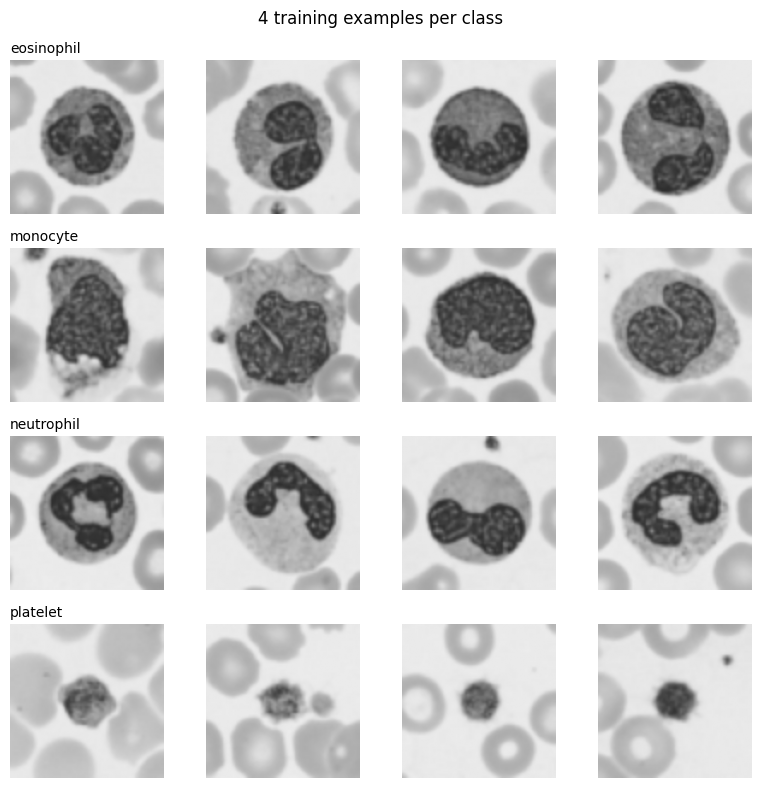

In [5]:
# One grid: 4 example images per class (rows = classes), as seen by the models (grayscale 128x128)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    ex = np.where(ytr == r)[0][:4]
    for c in range(4):
        axes[r, c].imshow(Xtr[ex[c]], cmap="gray", vmin=0, vmax=255)
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(NAMES[r], loc="left", fontsize=10)
plt.suptitle("4 training examples per class"); plt.tight_layout(); plt.show()

# Q2. HOG + SVM (6 marks)
## Q2 (a) HOG feature extraction and hand calculation

In [6]:
def hog_feat(img, visualize=False):
    im = img.astype(np.float32) / 255.0
    return hog(im, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2), block_norm="L2-Hys",
               feature_vector=True, visualize=visualize)

def hog_batch(X): return np.stack([hog_feat(im) for im in X])

Htr, Hva = hog_batch(Xtr), hog_batch(Xva)      # test HOG features are computed only in Q4
print("HOG feature matrix shapes -> train:", Htr.shape, " val:", Hva.shape)
print("HOG feature length (from code):", Htr.shape[1])

# check against the hand formula
cells_per_side  = 128 // HOG_CELL
blocks_per_side = cells_per_side - 2 + 1
hand_len = blocks_per_side**2 * (2 * 2 * 9)
print("HOG feature length (hand formula):", hand_len, "| match:", hand_len == Htr.shape[1])

HOG feature matrix shapes -> train: (400, 8100)  val: (120, 8100)
HOG feature length (from code): 8100
HOG feature length (hand formula): 8100 | match: True


**Hand calculation (cell size 8 x 8, my setting):**

1. Image is 128 x 128, cell is 8 x 8 -> 128 / 8 = **16 cells per side** (16 x 16 = 256 cells).
2. A block is 2 x 2 cells and moves by 1 cell, so blocks per side = 16 - 2 + 1 = **15** -> 15 x 15 = **225 blocks**.
3. Each block holds 2 x 2 cells x 9 orientation bins = **36 values**.
4. Total length = 225 blocks x 36 = **8100**.

The printed feature length above should be 8100.

## Q2 (b) HOG picture, one image per class

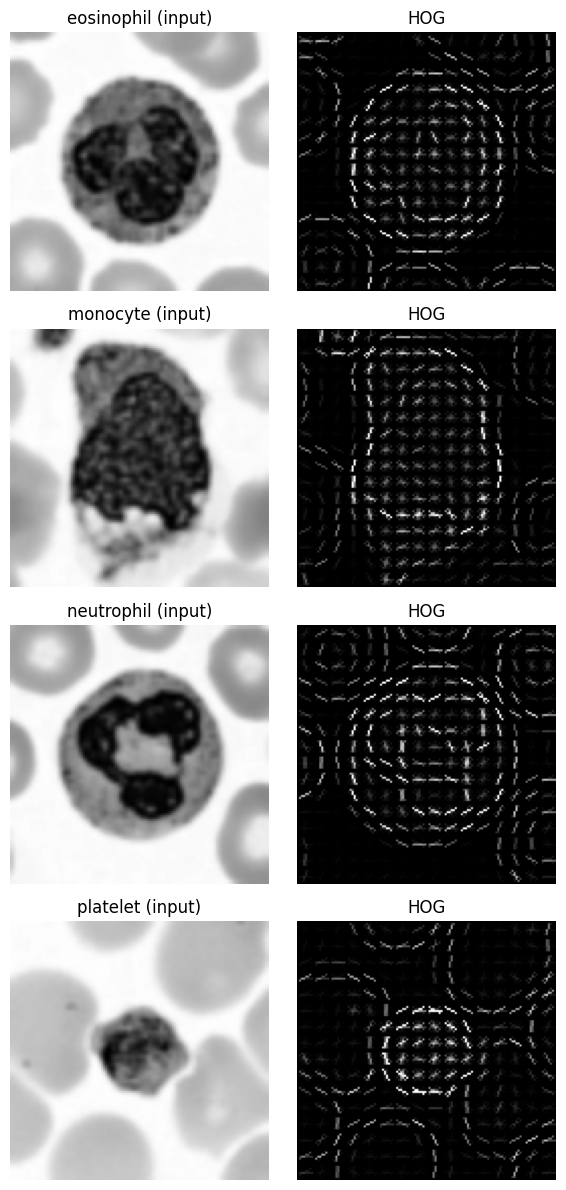

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(6, 12))
for r in range(4):
    i = np.where(ytr == r)[0][0]
    _, himg = hog_feat(Xtr[i], visualize=True)
    himg = exposure.rescale_intensity(himg, in_range=(0, np.percentile(himg, 99.5) + 1e-8))
    axes[r, 0].imshow(Xtr[i], cmap="gray"); axes[r, 0].set_title(f"{NAMES[r]} (input)"); axes[r, 0].axis("off")
    axes[r, 1].imshow(himg, cmap="gray");   axes[r, 1].set_title("HOG");               axes[r, 1].axis("off")
plt.tight_layout(); plt.show()

## Q2 (c) Train the SVM, choose C on the validation set

[HOG+SVM] C = 0.1  -> validation accuracy = 0.7000
[HOG+SVM] C = 1    -> validation accuracy = 0.7083
[HOG+SVM] C = 10   -> validation accuracy = 0.7083
[HOG+SVM] chosen C = 1
[HOG+SVM] validation accuracy = 0.7083 | macro-F1 = 0.7086
Confusion matrix (rows = true, cols = predicted):
 [[19  6  5  0]
 [ 5 21  4  0]
 [ 5  9 16  0]
 [ 1  0  0 29]]


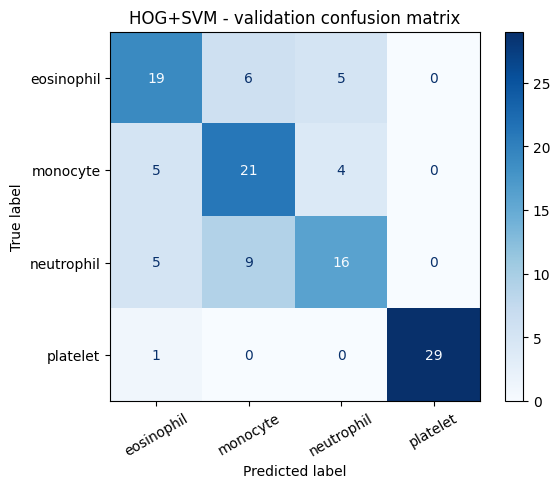

In [8]:
C_GRID = [0.1, 1, 10]

def fit_select_C(Ftr, ytr, Fva, yva, name):
    best = None
    for C in C_GRID:                                   # ascending: ties keep the smaller C
        clf = LinearSVC(C=C, max_iter=20000, random_state=SEED).fit(Ftr, ytr)
        acc = accuracy_score(yva, clf.predict(Fva))
        print(f"[{name}] C = {C:<4} -> validation accuracy = {acc:.4f}")
        if best is None or acc > best[0]:
            best = (acc, C, clf)
    print(f"[{name}] chosen C = {best[1]}")
    return best[2], best[1]

def report(clf, F, y, name):
    p = clf.predict(F)
    acc, f1 = accuracy_score(y, p), f1_score(y, p, average="macro")
    cm = confusion_matrix(y, p, labels=range(4))
    print(f"[{name}] validation accuracy = {acc:.4f} | macro-F1 = {f1:.4f}")
    print("Confusion matrix (rows = true, cols = predicted):\n", cm)
    ConfusionMatrixDisplay(cm, display_labels=NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(f"{name} - validation confusion matrix"); plt.show()
    return acc, f1, cm

hog_clf, hog_C = fit_select_C(Htr, ytr, Hva, yva, "HOG+SVM")
hog_val_acc, hog_val_f1, hog_cm = report(hog_clf, Hva, yva, "HOG+SVM")

# Q3. SIFT + SVM (7 marks)
## Q3 (a) Normal SIFT detection on the training images

Keypoints per training image -> average: 72.79, min: 9, max: 187
Images with zero keypoints  : 0 out of 400


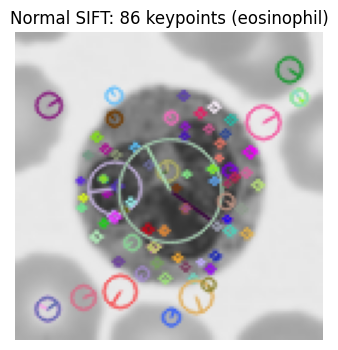

In [9]:
sift = cv2.SIFT_create()
n_kp = []
for im in Xtr:
    kps, des = sift.detectAndCompute(im, None)
    n_kp.append(len(kps))
n_kp = np.array(n_kp)
print(f"Keypoints per training image -> average: {n_kp.mean():.2f}, min: {n_kp.min()}, max: {n_kp.max()}")
print("Images with zero keypoints  :", int((n_kp == 0).sum()), "out of", len(n_kp))

i = 0
kps, _ = sift.detectAndCompute(Xtr[i], None)
vis = cv2.drawKeypoints(Xtr[i], kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(4, 4)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"Normal SIFT: {len(kps)} keypoints ({NAMES[ytr[i]]})"); plt.show()

**Why is a different number of keypoints per image a problem for an SVM?**
An SVM needs every image to be one feature vector of the *same length*, but normal SIFT gives an N x 128 descriptor matrix where N changes from image to image (and can be 0), so the descriptors cannot be stacked into one fixed-size feature matrix.

## Q3 (b) Fix: fixed grid of keypoints (dense SIFT)

SIFT-grid feature matrix shapes -> train: (400, 2048)  val: (120, 2048)
SIFT feature length (from code): 2048 | hand formula: 2048


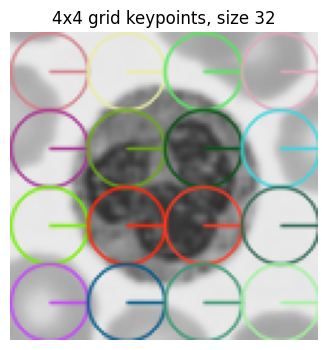

In [10]:
def grid_keypoints(grid=GRID, size=32, img_size=128):
    step = img_size / grid
    return [cv2.KeyPoint(float(step * (i + 0.5)), float(step * (j + 0.5)), float(size), 0.0)
            for j in range(grid) for i in range(grid)]          # row by row, centres of grid cells

def sift_grid_feat(img):
    kps, des = sift.compute(img, grid_keypoints())
    assert des.shape == (GRID * GRID, 128), des.shape
    return des.ravel()

def sift_batch(X): return np.stack([sift_grid_feat(im) for im in X])

Str, Sva = sift_batch(Xtr), sift_batch(Xva)
print("SIFT-grid feature matrix shapes -> train:", Str.shape, " val:", Sva.shape)
print("SIFT feature length (from code):", Str.shape[1], "| hand formula:", GRID * GRID * 128)

# picture of the grid keypoints on one image
vis = cv2.drawKeypoints(Xtr[0], grid_keypoints(), None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(4, 4)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"{GRID}x{GRID} grid keypoints, size 32"); plt.show()

**Hand calculation (4 x 4 grid, my setting):**
Grid points = 4 x 4 = **16**. Each SIFT descriptor has **128** values (4 x 4 spatial bins x 8 orientations).
Feature length = 16 x 128 = **2048**. The printed feature length above should be 2048.
Keypoints are placed at the centres of the 16 grid cells (x, y in {16, 48, 80, 112}), size 32, angle 0.

## Q3 (c) Train the SVM, choose C on the validation set

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


[SIFT+SVM] C = 0.1  -> validation accuracy = 0.7167


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


[SIFT+SVM] C = 1    -> validation accuracy = 0.7167


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


[SIFT+SVM] C = 10   -> validation accuracy = 0.7167
[SIFT+SVM] chosen C = 0.1
[SIFT+SVM] validation accuracy = 0.7167 | macro-F1 = 0.7188
Confusion matrix (rows = true, cols = predicted):
 [[15 11  4  0]
 [ 8 21  1  0]
 [ 7  1 21  1]
 [ 1  0  0 29]]


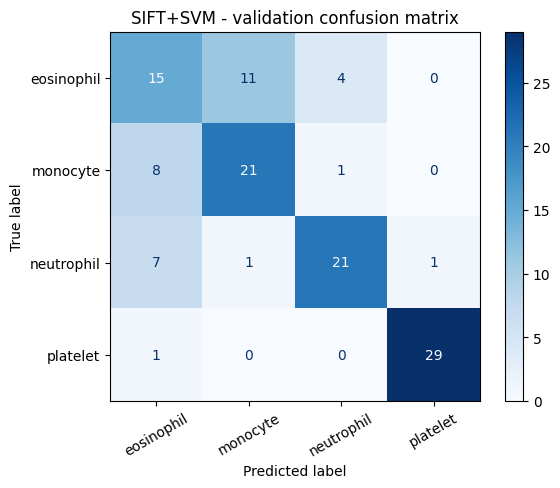

In [11]:
sift_clf, sift_C = fit_select_C(Str, ytr, Sva, yva, "SIFT+SVM")
sift_val_acc, sift_val_f1, sift_cm = report(sift_clf, Sva, yva, "SIFT+SVM")

# Q4. Robustness (6 marks)
## Q4 (a) Prediction (written BEFORE running the robustness test)
- **Rotation:** I think **HOG** will lose more accuracy. HOG's 8100 values are tied to exact cell positions and gradient directions (small 8 x 8 cells), so a 20 degree turn changes both. The grid SIFT uses large 32 x 32 patches with Gaussian weighting, so it changes less.
- **Noise:** I think **HOG** will lose more accuracy. Gradients are computed on single pixels and summed in tiny 8 x 8 cells, so noise adds many random gradients. SIFT patches are Gaussian-weighted over a larger area, which smooths the noise.

In [12]:
PRED_ROTATION = "HOG"     # same as the text above
PRED_NOISE    = "HOG"
print("Prediction -> rotation loses more:", PRED_ROTATION, "| noise loses more:", PRED_NOISE)

Prediction -> rotation loses more: HOG | noise loses more: HOG


## Q4 (b) Evaluate frozen models on the test set (clean, rotated 20 degrees, noisy sigma = 0.05)
Both models stay exactly as trained above (no re-training, no re-tuning). The change is applied to the **images** before feature extraction.

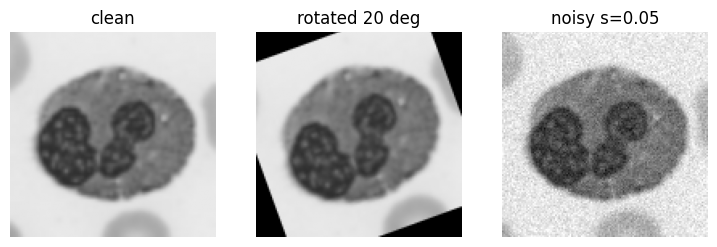

     Model  Clean accuracy  Rotated accuracy  Noisy accuracy
 HOG + SVM          0.7250            0.6667           0.625
SIFT + SVM          0.7167            0.3667           0.700

Accuracy drop (clean - changed):
     Model  Drop under rotation  Drop under noise
 HOG + SVM               0.0583            0.1000
SIFT + SVM               0.3500            0.0167

Lost more under rotation: SIFT (I predicted HOG) -> correct: False
Lost more under noise   : HOG (I predicted HOG) -> correct: True


In [13]:
def rotate(img, angle=20):
    M = cv2.getRotationMatrix2D((64, 64), angle, 1.0)
    return cv2.warpAffine(img, M, (128, 128), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=0)

def add_noise(X, sigma=0.05, seed=SEED):
    r = np.random.RandomState(seed)
    x = X.astype(np.float32) / 255.0                       # scale to 0..1
    x = np.clip(x + r.normal(0, sigma, x.shape), 0, 1)
    return (x * 255).round().astype(np.uint8)

Xte_rot   = np.stack([rotate(im, 20) for im in Xte])
Xte_noisy = add_noise(Xte, 0.05)

# sanity picture: same test image in the three cases
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, im, t in zip(ax, [Xte[0], Xte_rot[0], Xte_noisy[0]], ["clean", "rotated 20 deg", "noisy s=0.05"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
plt.show()

def evaluate(X):
    return (accuracy_score(yte, hog_clf.predict(hog_batch(X))),
            accuracy_score(yte, sift_clf.predict(sift_batch(X))))

res = {case: evaluate(X) for case, X in [("Clean", Xte), ("Rotated", Xte_rot), ("Noisy", Xte_noisy)]}
table = pd.DataFrame({
    "Model": ["HOG + SVM", "SIFT + SVM"],
    "Clean accuracy":   [res["Clean"][0],   res["Clean"][1]],
    "Rotated accuracy": [res["Rotated"][0], res["Rotated"][1]],
    "Noisy accuracy":   [res["Noisy"][0],   res["Noisy"][1]],
}).round(4)
print(table.to_string(index=False))

drops = pd.DataFrame({
    "Model": ["HOG + SVM", "SIFT + SVM"],
    "Drop under rotation": (table["Clean accuracy"] - table["Rotated accuracy"]).round(4),
    "Drop under noise":    (table["Clean accuracy"] - table["Noisy accuracy"]).round(4),
})
print("\nAccuracy drop (clean - changed):"); print(drops.to_string(index=False))

worse_rot   = "HOG" if drops.iloc[0, 1] > drops.iloc[1, 1] else ("SIFT" if drops.iloc[1, 1] > drops.iloc[0, 1] else "tie")
worse_noise = "HOG" if drops.iloc[0, 2] > drops.iloc[1, 2] else ("SIFT" if drops.iloc[1, 2] > drops.iloc[0, 2] else "tie")
print(f"\nLost more under rotation: {worse_rot} (I predicted {PRED_ROTATION}) -> correct: {worse_rot == PRED_ROTATION}")
print(f"Lost more under noise   : {worse_noise} (I predicted {PRED_NOISE}) -> correct: {worse_noise == PRED_NOISE}")

## Q4 (c) Was my prediction correct?

Under rotation, HOG accuracy went from 0.7250 to 0.6667 (drop = 0.0583) while SIFT accuracy went from 0.7167 to 0.3667 (drop = 0.3500), so SIFT lost more and my rotation prediction (HOG) was wrong. Under noise, HOG accuracy went from 0.7250 to 0.6250 (drop = 0.1000) while SIFT accuracy went from 0.7167 to 0.7000 (drop = 0.0167), so HOG lost more and my noise prediction was correct. A likely reason is that the grid SIFT keypoints were fixed upright (angle 0), so turning the image by 20 degrees changed its descriptors a lot, while SIFT's larger smoothed 32 x 32 patches handled noise much better than HOG's small 8 x 8 cells.

# Q5. Short answers and AI log (3 marks)
## Q5 (1) Short answers
**(a) Why does HOG use block normalisation?**
Gradient strength changes with local brightness and contrast (for example different staining or lighting), even when the cell shape is the same. HOG normalises the histograms of each overlapping block of cells, so the descriptor depends on the pattern of gradient directions instead of their absolute strength. This makes features comparable between bright and dark images and helps the SVM.

**(b) Why is it wrong to choose C using the test set?**
The test set is only meant to give an honest estimate of performance on unseen data. If I pick the C that scores best on the test set, information from the test set leaks into the model choice. The reported test accuracy then becomes too optimistic. C must be chosen on the validation set, and the test set used once at the end.

## Q5 (2) Most confused classes (from validation confusion matrices, test set not used)

In [14]:
def top_confused_pair(cm):
    best = (0, None)
    for a in range(4):
        for b in range(a + 1, 4):
            n = cm[a, b] + cm[b, a]
            if n > best[0]: best = (n, (a, b))
    return best

for name, cm in [("HOG+SVM", hog_cm), ("SIFT+SVM", sift_cm)]:
    n, pair = top_confused_pair(cm)
    if pair is None:
        print(f"{name}: no confusion between any pair")
    else:
        print(f"{name}: most confused pair = {NAMES[pair[0]]} <-> {NAMES[pair[1]]} "
              f"({cm[pair[0], pair[1]]} + {cm[pair[1], pair[0]]} = {n} wrong predictions)")

HOG+SVM: most confused pair = monocyte <-> neutrophil (4 + 9 = 13 wrong predictions)
SIFT+SVM: most confused pair = eosinophil <-> monocyte (11 + 8 = 19 wrong predictions)


On the validation confusion matrices, HOG + SVM confused monocyte and neutrophil the most (4 + 9 = 13 wrong predictions), while SIFT + SVM confused eosinophil and monocyte the most (11 + 8 = 19 wrong predictions). Monocyte appears in the most confused pair of both models. These cells are similar in shape and texture: they are roundish cells with a lobed or bean-shaped nucleus, and one of the main differences between them is colour (for example, eosinophil granules are red-orange). Grayscale removes colour, so only shape and texture are left, and these look very alike, which makes the classes harder to separate.

## Q5 (3) AI log

| # | Prompt (one line) | What I changed | How I checked it was correct |
|---|-------------------|----------------|------------------------------|
| 1 | "Solve this lab mid for reg no 022 and give me the notebook files" (I uploaded the exam PDF) | I ran the notebook myself in Google Colab with my own settings (seed 22, HOG cell 8x8, 4x4 SIFT grid) | I printed the seed, cell size and grid size in the first code cell and compared them with the exam rules |
| 2 | "Explain step by step how to run it and what each part does" | I followed the steps in Colab and fixed the Drive quota problem by opening the notebook another way | I checked that all cells ran without a red error and that the shapes and feature lengths printed |
| 3 | "Tell me what to write in the Q4(c) blanks" (I shared a screenshot of my table) | I took the accuracy numbers from my own printed table and pasted the paragraph into the Q4(c) cell | I compared every number in the paragraph with my printed accuracy table, drop table and the correct True/False lines |
| 4 | "Write the Q5 confused-pair answer from my printed output" (I shared a screenshot) | I used the pairs and counts printed by my own notebook | I compared the class names and wrong-prediction counts with the lines in my output |